# EKF G/F con solubilidad variable · R fijo y dependiente del volumen

Se comparan dos ejecuciones del mismo EKF, con los mismos datos, máscaras de actualización, condiciones iniciales, química, parámetros de gas y \(Q\). El caso fijo reproduce el escenario de la ficha técnica del notebook 02. LAB019–021 son los lotes de desarrollo y LAB016–018 los de validación. La preparación de esos lotes se replica del notebook 02 y no se ajustan parámetros.

Los dos casos parten del escenario de ±4 % del fondo de escala de 50 SCCM y de una distribución uniforme, supuestos que permiten calcular \(R_{\rm SCCM}=2^2/3\;\mathrm{SCCM}^2\). La ficha técnica deja sin especificar la base de ese porcentaje. La comparación examina la propagación por volumen de esa incertidumbre de conversión.

In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nbformat
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/wine_fermentation').is_dir())
HERE=ROOT/'notebooks/EKF/kalman_analysis'
sys.path.insert(0,str(HERE))
import analysis_core as core
INSTRUMENT=json.loads((ROOT/'configs/co2_instrument.json').read_text())
assert INSTRUMENT['flow_range_sccm']==[0.,50.] and INSTRUMENT['calibration_gas']=='air'
assert INSTRUMENT['co2_correction_factor']==.74
DATA,CHEM,AUDIT,_=core.prepare(ROOT)
assert tuple(DATA)==('LAB019','LAB020','LAB021') and set(CHEM.lab)==set(DATA)
DEVELOPMENT=tuple(DATA)
HOLDOUT=('LAB016','LAB017','LAB018')
LABS=DEVELOPMENT+HOLDOUT
ROLE={lab:('Development' if lab in DEVELOPMENT else 'Holdout') for lab in LABS}
# Reuse the same clock corrections, horizons and holdout metadata as EKF05.
# load() prepares observations and metadata; it does not calibrate gas or chemistry.
sys.path.insert(0,str(ROOT/'src'))
from wine_fermentation.models.historical.calibration import load
v=load(ROOT)
volume_rows=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','remaining_volume_L'])
extra_audit=[]
for lab in HOLDOUT:
    horizon=float(v.horizons[lab]);batch=v.batches[lab]
    events=list(batch.pulses['N'])
    if lab=='LAB017':events=[(min(t for t,dose in events),sum(dose for t,dose in events))]
    events=np.array([(round(t,10),dose) for t,dose in events],float)
    ev=volume_rows.loc[volume_rows.lab.eq(lab)&volume_rows.record_kind.eq('withdrawal_after')].sort_values('time_h')
    et=ev.time_h.to_numpy();vv=ev.remaining_volume_L.to_numpy()
    def volume(t):return np.r_[2.,vv][np.searchsorted(et,np.asarray(t),side='right')]
    raw=v.raw_co2[lab].copy();raw['bin']=np.ceil(raw.t_h/.5-1e-10).astype(int);rows=[]
    for end in np.arange(.5,horizon+1e-9,.5):
        sample=raw.loc[raw.bin.eq(round(end/.5))].dropna(subset=['flow_sccm'])
        gaps=np.diff(np.r_[end-.5,sample.t_h.to_numpy(),end])
        y=sample.flow_sccm.to_numpy()*(44.0095*60*.74/(1000*24.16))/volume(sample.t_h.to_numpy())
        rows.append((end,float(np.mean(y)) if len(y) else np.nan,len(sample)>=30 and gaps.max()<=2/60))
    sensor=pd.DataFrame(rows,columns=['t_h','measured','valid'])
    sensor['assimilate']=sensor.valid&sensor.measured.ge(.05)&sensor.valid.shift(fill_value=False)&sensor.measured.shift().ge(.05)
    rawt=v.raw_temperature[lab].copy();rawt['minute']=np.floor(rawt.t_h*60).astype(int)
    temp=rawt.groupby('minute')['T'].median().dropna();available=(temp.index.to_numpy()+1)/60;temps=temp.to_numpy(float)
    initial=np.array([batch.initials[k] for k in core.STATES[:5]]+[0.,0.]);initial[4]=10.010194;S0=initial[2]+initial[3]
    r=initial[2]/S0
    P0=np.diag([max(.03,.2*initial[0])**2,.015**2,r*r*25+25,(1-r)**2*25+25,4.,0.,0.]);P0[2,3]=P0[3,2]=r*(1-r)*25-25
    grid=np.unique(np.round(np.r_[np.arange(0,horizon,1/12),sensor.t_h,horizon,events[:,0]],10))
    doses=np.zeros(len(grid));obs=np.full(len(grid),np.nan);valid=np.zeros(len(grid),bool);update=np.zeros(len(grid),bool)
    for t,dose in events:doses[np.argmin(abs(grid-t))]+=dose
    for row in sensor.itertuples():
        j=np.argmin(abs(grid-row.t_h));assert abs(grid[j]-row.t_h)<1e-8
        obs[j]=row.measured;valid[j]=row.valid;update[j]=row.assimilate
    DATA[lab]=dict(grid=grid,doses=doses,y=obs,valid=valid,update=update,initial=initial,P0=P0,available=available,temperature=temps,S0=S0,sensor=sensor,horizon=horizon)
    extra_audit.append(dict(LAB=lab,horizon_h=horizon,windows=len(sensor),updates=int(sensor.assimilate.sum()),X0=initial[0],N0=initial[1],G0=initial[2],F0=initial[3],E0=initial[4],pulse_h=events[0,0],dose_g_L=events[0,1]))
# Only actual holdout biomass observations are appended; missing chemistry is not invented.
CHEM=pd.concat([CHEM,v.biomass.loc[v.biomass.lab.isin(HOLDOUT),['lab','t_h','X_viable_g_l']]],ignore_index=True)
DENSITY=v.density.loc[v.density.lab.isin(LABS)].copy()
AUDIT=pd.concat([AUDIT,pd.DataFrame(extra_audit)],ignore_index=True);AUDIT['role']=AUDIT.LAB.map(ROLE)
assert tuple(DATA)==LABS
display(AUDIT)


,LAB,horizon_h,windows,updates,X0,N0,G0,F0,E0,pulse_h,dose_g_L,role
0,LAB019,166.000000,332,217,0.283162,0.230025,79.190000,78.970000,10.010194,64.333333,0.086486,Development
1,LAB020,172.333333,344,223,0.153342,0.225556,77.940000,79.520000,10.010194,71.666667,0.088889,Development
2,LAB021,166.000000,332,166,0.270000,0.231202,80.190000,81.040000,10.010194,47.500000,0.086486,Development
3,LAB016,151.100000,302,249,0.390000,0.214330,84.158815,88.341185,10.010194,56.935556,0.140000,Holdout
4,LAB017,141.000000,282,213,0.390000,0.214330,84.158815,88.341185,10.010194,56.933611,0.280000,Holdout
5,LAB018,141.000000,282,237,0.390000,0.214330,84.158815,88.341185,10.010194,56.931667,0.140000,Holdout


## Propagación a cada ventana de 30 minutos

Sea \(c_2\) el factor de conversión a 2 L. El caso fijo usa \(R_2=c_2^2 R_{\rm SCCM}\). El caso variable usa \(R_k=R_2\,(\overline{2\,\mathrm L/V_i})^2\), promediando sobre las mismas lecturas \(i\) que forman la observación de la ventana \(k\). Si el volumen es constante en la ventana, se recupera \(R(V)=R_2(2\,\mathrm L/V)^2\).

Para propagar el componente de exactitud se supone un error común a las lecturas de la ventana. Con este supuesto, un cambio de volumen dentro de la ventana se trata con el promedio de los factores de conversión y el componente no se divide por el número de muestras. El supuesto dentro de la ventana no caracteriza la correlación entre ventanas. Ambos escenarios se usan como parametrizaciones del EKF.

In [2]:
reference_volume = 2.0
flow_limit = 0.04 * INSTRUMENT['flow_range_sccm'][1]
R_sccm = flow_limit**2 / 3
c2 = 44.0095 * 60 * INSTRUMENT['co2_correction_factor'] / (1000 * 24.16 * reference_volume)
R_fixed = c2**2 * R_sccm
np.testing.assert_allclose(R_fixed, 0.002180437761, rtol=1e-8)

raw_development = core.recent_raw(
    ROOT/'data/original/natural/lab019_021/backup_global_co2_completo.csv',
    ['timestamp', 'fermentador', 'flow_sccm'],
)
raw_by_lab = {
    lab: raw_development.loc[raw_development.fermentador.eq(f'F{i}')]
    for i, lab in enumerate(DEVELOPMENT, 1)
}
raw_by_lab.update({lab: v.raw_co2[lab] for lab in HOLDOUT})

R_by_lab = {}
window_rows = []
for lab in LABS:
    data = DATA[lab]
    raw = raw_by_lab[lab][['t_h', 'flow_sccm']].dropna().copy()
    events = volume_rows.loc[
        volume_rows.lab.eq(lab) & volume_rows.record_kind.eq('withdrawal_after')
    ].sort_values('time_h')
    event_index = np.searchsorted(events.time_h.to_numpy(), raw.t_h, side='right')
    volume = np.r_[reference_volume, events.remaining_volume_L.to_numpy()][event_index]
    assert np.all(np.isfinite(volume) & (volume > 0))
    raw['window'] = np.ceil(raw.t_h / 0.5 - 1e-10).astype(int)
    raw['factor_ratio'] = reference_volume / volume
    raw['volume'] = volume
    raw['converted'] = raw.flow_sccm * c2 * raw.factor_ratio
    grouped = raw.groupby('window').agg(
        observed=('converted', 'mean'), factor_ratio=('factor_ratio', 'mean'),
        min_volume=('volume', 'min'), max_volume=('volume', 'max'),
    )
    windows = data['sensor'].copy()
    windows['window'] = np.rint(windows.t_h / 0.5).astype(int)
    windows = windows.join(grouped, on='window')
    np.testing.assert_allclose(windows.measured, windows.observed, rtol=1e-12, atol=1e-12)
    windows['R_variable'] = R_fixed * windows.factor_ratio**2
    windows['LAB'] = lab
    window_rows.append(windows.loc[windows.assimilate])

    used = windows.loc[windows.assimilate]
    indices = np.searchsorted(data['grid'], used.t_h)
    np.testing.assert_array_equal(indices, np.flatnonzero(data['update']))
    r = np.full(len(data['grid']), R_fixed)
    r[indices] = used.R_variable
    R_by_lab[lab] = r

WINDOWS = pd.concat(window_rows, ignore_index=True)
assert WINDOWS.R_variable.notna().all()
WINDOWS['volume_changes'] = WINDOWS.min_volume.ne(WINDOWS.max_volume)
display(WINDOWS.groupby('LAB').agg(
    actualizaciones=('R_variable', 'size'), volumen_min_L=('min_volume', 'min'),
    ventanas_con_cambio=('volume_changes', 'sum'), R_min=('R_variable', 'min'),
    R_mediana=('R_variable', 'median'), R_max=('R_variable', 'max'),
))

,actualizaciones,volumen_min_L,ventanas_con_cambio,R_min,R_mediana,R_max
LAB,,,,,,
LAB016,249,2.00,0,0.002180,0.002180,0.002180
LAB017,213,2.00,0,0.002180,0.002180,0.002180
LAB018,237,2.00,0,0.002180,0.002180,0.002180
LAB019,217,1.75,0,0.002294,0.002692,0.002848
LAB020,223,1.75,0,0.002416,0.002848,0.002848
LAB021,166,1.75,0,0.002294,0.002548,0.002848


In [3]:
FIXED, VARIABLE = 'Fijo', 'Por volumen'
RESULTS = {FIXED: {}, VARIABLE: {}}
metric_rows, checks = [], []
for lab in LABS:
    data = DATA[lab]
    for case, variance in [(FIXED, R_fixed), (VARIABLE, R_by_lab[lab])]:
        result = core.run(data, Rsd=np.sqrt(variance))
        RESULTS[case][lab] = result
        metrics, info, _ = core.diagnostics(DATA, CHEM, lab, result)
        metric_rows.append(metrics.assign(caso=case, grupo=ROLE[lab]))
        checks.append(dict(info, caso=case, grupo=ROLE[lab]))
        if case == FIXED:
            constant_array = np.full(data['grid'].shape, np.sqrt(R_fixed))
            for actual, expected in zip(core.run(data, Rsd=constant_array), result):
                np.testing.assert_array_equal(actual, expected)

METRICS = pd.concat(metric_rows, ignore_index=True)
CHECKS = pd.DataFrame(checks)
keys = ['grupo', 'LAB', 'variable', 'unit']
counts = METRICS.pivot(index=keys, columns='caso', values='n')
assert counts[FIXED].equals(counts[VARIABLE])
assert CHECKS.min_eigenvalue.min() > -1e-7

mean = METRICS.groupby(['grupo', 'variable', 'unit', 'caso']).RMSE.mean().unstack('caso')
# Verify the fixed case against the precision published in notebook 02.
published = {
    ('Development', 'CO2', 'g/(L h)'): 0.0740,
    ('Development', 'E', 'g/L'): 3.6546,
    ('Development', 'F', 'g/L'): 5.3210,
    ('Development', 'G', 'g/L'): 4.9913,
    ('Development', 'GF', 'g/L'): 8.1811,
    ('Development', 'N', 'mg/L'): 17.1217,
    ('Development', 'X', 'g/L'): 0.7199,
    ('Holdout', 'CO2', 'g/(L h)'): 0.0800,
    ('Holdout', 'X', 'g/L'): 0.6174,
}
for key, expected in published.items():
    np.testing.assert_allclose(mean.loc[key, FIXED], expected, rtol=0, atol=0.00005)

def add_delta(table):
    return table.assign(**{'Cambio (%)': 100 * (table[VARIABLE] / table[FIXED] - 1)})

for metric in ('RMSE', 'MAE'):
    grouped = METRICS.groupby(['grupo', 'variable', 'unit', 'caso'])[metric].mean().unstack('caso')
    by_lab = METRICS.pivot(index=keys, columns='caso', values=metric)
    print(f'{metric} medio por grupo. Cada lote tiene el mismo peso.')
    display(add_delta(grouped[[FIXED, VARIABLE]]).round(5))
    print(f'{metric} por lote. X corresponde a biomasa.')
    display(add_delta(by_lab[[FIXED, VARIABLE]]).round(5))
print('Diagnosticos por lote en las ventanas asimiladas.')
display(CHECKS[['grupo', 'LAB', 'caso', 'updates', 'mean_NIS',
                'innovation_coverage95', 'lag1', 'clips']].round(4))

RMSE medio por grupo. Cada lote tiene el mismo peso.
RMSE por lote. X corresponde a biomasa.
MAE medio por grupo. Cada lote tiene el mismo peso.
MAE por lote. X corresponde a biomasa.
Diagnosticos por lote en las ventanas asimiladas.


caso                              Fijo  Por volumen  Cambio (%)
grupo       variable unit                                      
Development CO2      g/(L h)   0.07399      0.07354    -0.61238
            E        g/L       3.65465      3.67206     0.47632
            F        g/L       5.32104      5.29385    -0.51104
            G        g/L       4.99132      5.04098     0.99479
            GF       g/L       8.18115      8.18655     0.06607
            N        mg/L     17.12172     17.05791    -0.37269
            X        g/L       0.71986      0.71770    -0.29976
Holdout     CO2      g/(L h)   0.08002      0.08002     0.00000
            X        g/L       0.61737      0.61737     0.00000

caso                                     Fijo  Por volumen  Cambio (%)
grupo       LAB    variable unit                                      
Development LAB019 CO2      g/(L h)   0.06390      0.06329    -0.96080
                   E        g/L       4.31332      4.30775    -0.12914
                   F        g/L       5.33379      5.26270    -1.33280
                   G        g/L       4.24218      4.35926     2.75983
                   GF       g/L       7.98079      8.00491     0.30217
                   N        mg/L     20.01465     19.91697    -0.48804
                   X        g/L       0.65490      0.65316    -0.26581
            LAB020 CO2      g/(L h)   0.07034      0.06932    -1.45067
                   E        g/L       3.52067      3.56809     1.34687
                   F        g/L       6.08460      6.05450    -0.49478
                   G        g/L       4.53788      4.62211     1.85614
                   GF       g/L       8.25179      8.24068    -0.13470
                   N        mg/L     18.11158     17.99933    -0.61976
                   X        g/L       0.57051      0.56994    -0.09909
            LAB021 CO2      g/(L h)   0.08772      0.08800     0.31361
                   E        g/L       3.12996      3.14034     0.33150
                   F        g/L       4.54473      4.56434     0.43160
                   G        g/L       6.19390      6.14156    -0.84513
                   GF       g/L       8.31085      8.31407     0.03868
                   N        mg/L     13.23894     13.25743     0.13970
                   X        g/L       0.93417      0.93000    -0.44612
Holdout     LAB016 CO2      g/(L h)   0.07386      0.07386     0.00000
                   X        g/L       0.56065      0.56065     0.00000
            LAB017 CO2      g/(L h)   0.08750      0.08750     0.00000
                   X        g/L       0.81125      0.81125     0.00000
            LAB018 CO2      g/(L h)   0.07870      0.07870     0.00000
                   X        g/L       0.48022      0.48022     0.00000

caso                              Fijo  Por volumen  Cambio (%)
grupo       variable unit                                      
Development CO2      g/(L h)   0.05176      0.05146    -0.59125
            E        g/L       3.15988      3.16431     0.14042
            F        g/L       4.94281      4.91937    -0.47436
            G        g/L       4.27196      4.31543     1.01763
            GF       g/L       7.37430      7.36184    -0.16890
            N        mg/L     12.74210     12.71010    -0.25116
            X        g/L       0.53484      0.53212    -0.50862
Holdout     CO2      g/(L h)   0.06080      0.06080     0.00000
            X        g/L       0.56702      0.56702     0.00000

caso                                     Fijo  Por volumen  Cambio (%)
grupo       LAB    variable unit                                      
Development LAB019 CO2      g/(L h)   0.04792      0.04755    -0.77883
                   E        g/L       3.41114      3.39039    -0.60837
                   F        g/L       5.19783      5.12984    -1.30790
                   G        g/L       3.41047      3.51037     2.92938
                   GF       g/L       7.13462      7.14704     0.17410
                   N        mg/L     15.89653     15.84262    -0.33916
                   X        g/L       0.53405      0.53159    -0.46074
            LAB020 CO2      g/(L h)   0.05611      0.05530    -1.44522
                   E        g/L       3.22804      3.27909     1.58149
                   F        g/L       5.89753      5.85626    -0.69992
                   G        g/L       4.03980      4.11099     1.76228
                   GF       g/L       7.42449      7.38350    -0.55217
                   N        mg/L     14.24204     14.16668    -0.52916
                   X        g/L       0.39871      0.39698    -0.43367
            LAB021 CO2      g/(L h)   0.05126      0.05152     0.51898
                   E        g/L       2.84045      2.82346    -0.59806
                   F        g/L       3.73308      3.77200     1.04258
                   G        g/L       5.36562      5.32494    -0.75816
                   GF       g/L       7.56379      7.55499    -0.11622
                   N        mg/L      8.08774      8.12101     0.41132
                   X        g/L       0.67175      0.66778    -0.59117
Holdout     LAB016 CO2      g/(L h)   0.05303      0.05303     0.00000
                   X        g/L       0.50104      0.50104     0.00000
            LAB017 CO2      g/(L h)   0.07315      0.07315     0.00000
                   X        g/L       0.72264      0.72264     0.00000
            LAB018 CO2      g/(L h)   0.05622      0.05622     0.00000
                   X        g/L       0.47738      0.47738     0.00000

,grupo,LAB,caso,updates,mean_NIS,innovation_coverage95,lag1,clips
0,Development,LAB019,Fijo,217,1.1694,0.9493,0.8049,57
1,Development,LAB019,Por volumen,217,1.0398,0.9539,0.8016,52
2,Development,LAB020,Fijo,223,1.1299,0.9552,0.7349,16
3,Development,LAB020,Por volumen,223,0.9992,0.9641,0.7343,17
4,Development,LAB021,Fijo,166,3.0736,0.7530,0.9172,24
5,Development,LAB021,Por volumen,166,2.8811,0.7831,0.9182,24
6,Holdout,LAB016,Fijo,249,1.2043,0.9036,0.8673,156
7,Holdout,LAB016,Por volumen,249,1.2043,0.9036,0.8673,156
8,Holdout,LAB017,Fijo,213,1.8893,0.9014,0.8015,216
9,Holdout,LAB017,Por volumen,213,1.8893,0.9014,0.8015,216


## Trayectorias por lote

Los paneles muestran las trayectorias para \(R\) fijo y \(R\) por volumen, las observaciones disponibles y los pulsos de nitrógeno. El RMSE y el MAE se muestran en las unidades del eje vertical. Para los estados químicos, el punto inicial se muestra como referencia y las métricas usan las muestras posteriores. El CO₂ disuelto se muestra como estado estimado y carece de mediciones de referencia.

In [4]:
COLORS={FIXED:'#0072B2',VARIABLE:'#D55E00'}
STYLES={FIXED:'-',VARIABLE:'--'}
def compare(state,title):
    factor=1000 if state=='N' else 1.
    unit='g/(L h)' if state=='CO2' else ('mg/L' if state=='N' else 'g/L')
    fig,axs=plt.subplots(2,3,figsize=(15,7.6))
    for ax,lab in zip(axs.flat,LABS):
        d=DATA[lab];errors=[]
        for label in (FIXED, VARIABLE):
            f,_,dg=RESULTS[label][lab]
            if state=='CO2':
                mask=d['valid']&np.isfinite(dg[:,0]);tx=d['grid'][mask];pred=dg[mask,0]
            else:
                tx=d['grid'];pred=f[:,2]+f[:,3] if state=='GF' else f[:,core.STATES.index(state)]
            ax.plot(tx,pred*factor,color=COLORS[label],ls=STYLES[label],label=label,lw=1.5)
            row=METRICS.loc[METRICS.LAB.eq(lab)&METRICS.variable.eq(state)&METRICS.caso.eq(label)]
            if len(row):
                rmse, mae = row[['RMSE', 'MAE']].iloc[0]
                errors.append(f'{label} · RMSE {rmse:.4f} · MAE {mae:.4f}')
        if state=='CO2':
            sensor=d['sensor'];ax.plot(sensor.t_h,sensor.measured,c='black',lw=.7,label='Mediciones')
        elif state!='Cd':
            col=core.CHEM_COLS[state]
            o=CHEM.loc[CHEM.lab.eq(lab)&CHEM.t_h.gt(0)&CHEM.t_h.le(d['horizon'])].dropna(subset=[col])
            if state=='GF':o=o.loc[~o.GF_zero_substitution.astype(str).str.lower().eq('true')]
            sample_label='G+F' if state=='GF' else 'Mediciones'
            ax.scatter(o.t_h,o[col]*factor,c='black',s=22,label=sample_label,zorder=5)
            initial=d['initial'][2]+d['initial'][3] if state=='GF' else d['initial'][core.STATES.index(state)]
            ax.scatter([0],[initial*factor],c='black',s=22,zorder=5)
            if state=='GF':
                density=DENSITY
                density=density.loc[density.lab.eq(lab)&density.t_h.between(0,d['horizon'])].dropna(subset=['density_g_l'])
                ax.scatter(density.t_h,2.5*(density.density_g_l-1000),marker='D',facecolors='none',edgecolors='#009E73',s=23,label='G+F por densidad',zorder=4)
        for t in d['grid'][d['doses']>0]:ax.axvline(t,c='gray',ls=':',lw=.8,label='Pulso de N')
        h,l=ax.get_legend_handles_labels();unique=dict(zip(l,h))
        ax.legend(unique.values(),unique.keys(),loc='best',fontsize=6.8,title='\n'.join(errors) or None,title_fontsize=7,framealpha=.9)
        ax.set(title=lab+' · '+ROLE[lab],xlabel='Tiempo [h]',ylabel=title+' ['+unit+']');ax.grid(alpha=.2)
    context='predicción antes de corregir' if state=='CO2' else 'estimación del estado'
    fig.suptitle(f'{title} · EKF G/F · {context} · R fijo y por volumen',y=.995)
    fig.tight_layout(pad=.7,rect=(0,0,1,.95))
    plt.show()


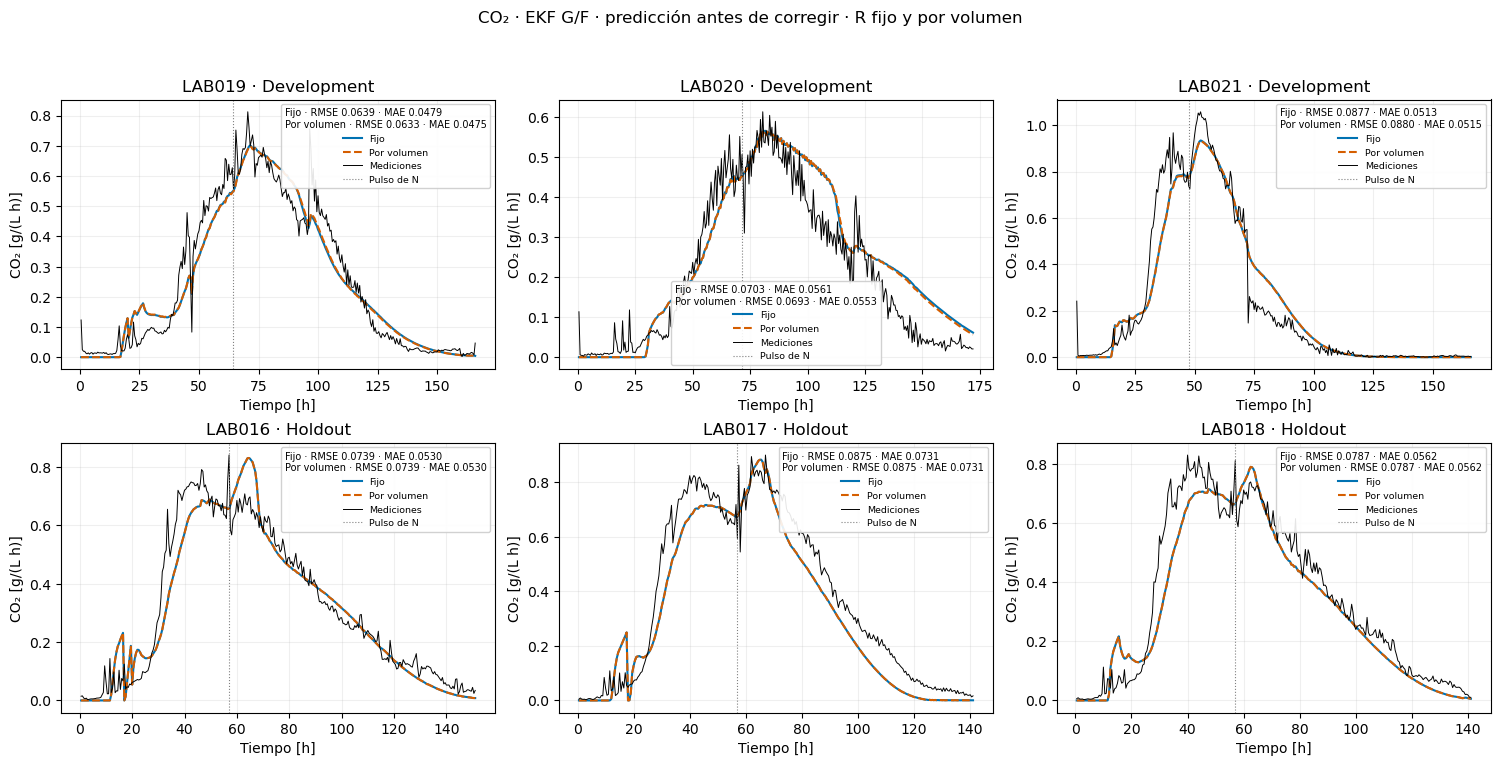

In [5]:
compare('CO2', 'CO₂')

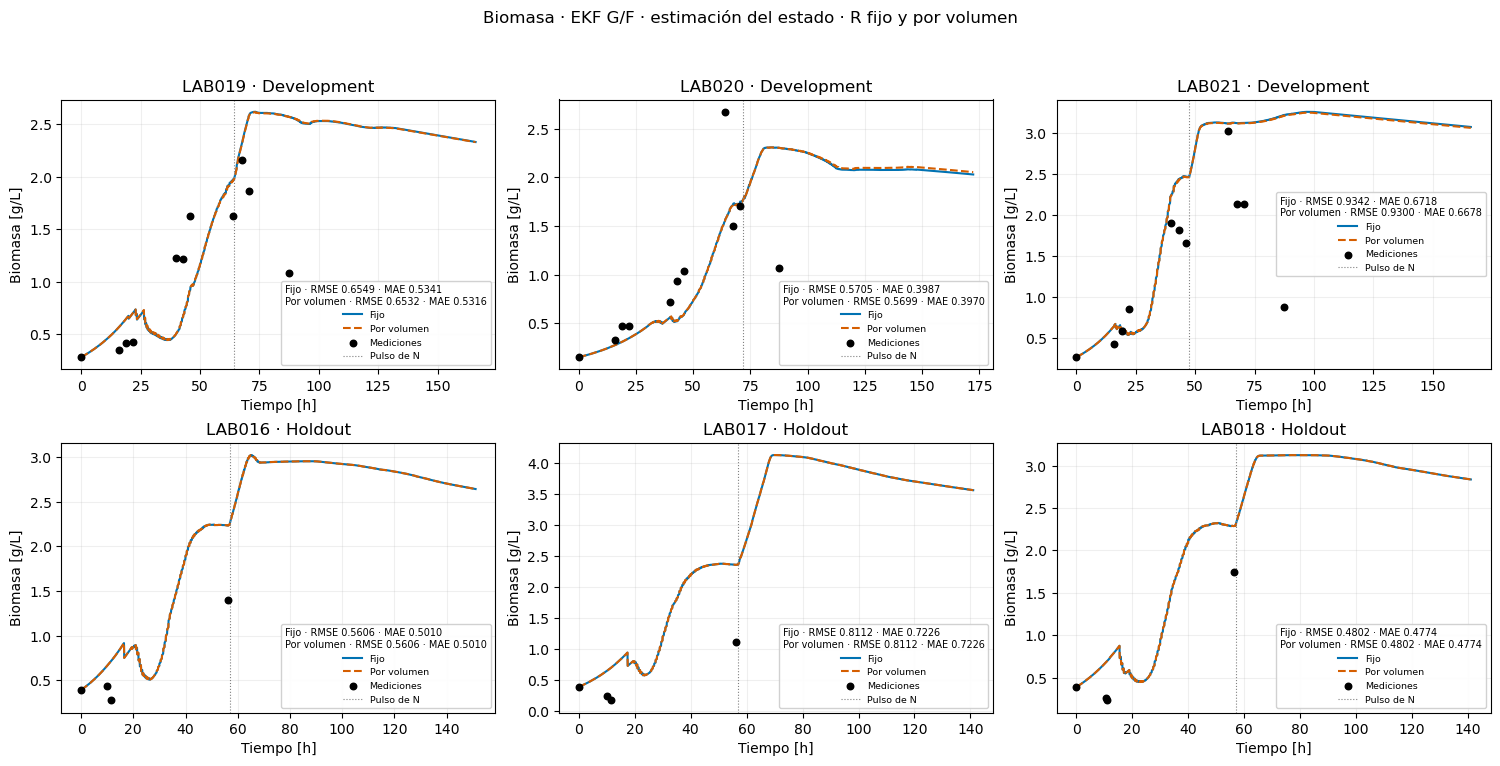

In [6]:
compare('X', 'Biomasa')

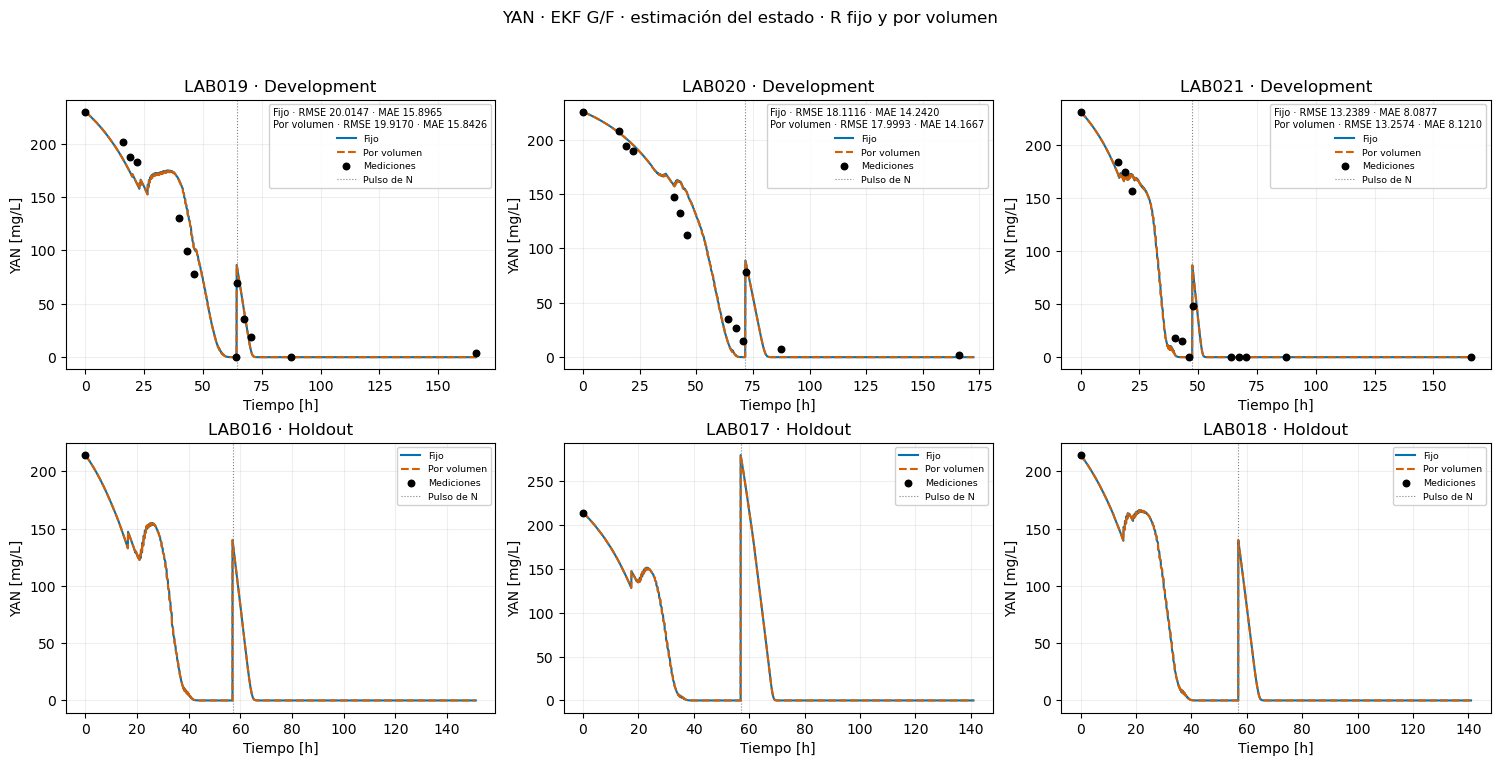

In [7]:
compare('N', 'YAN')

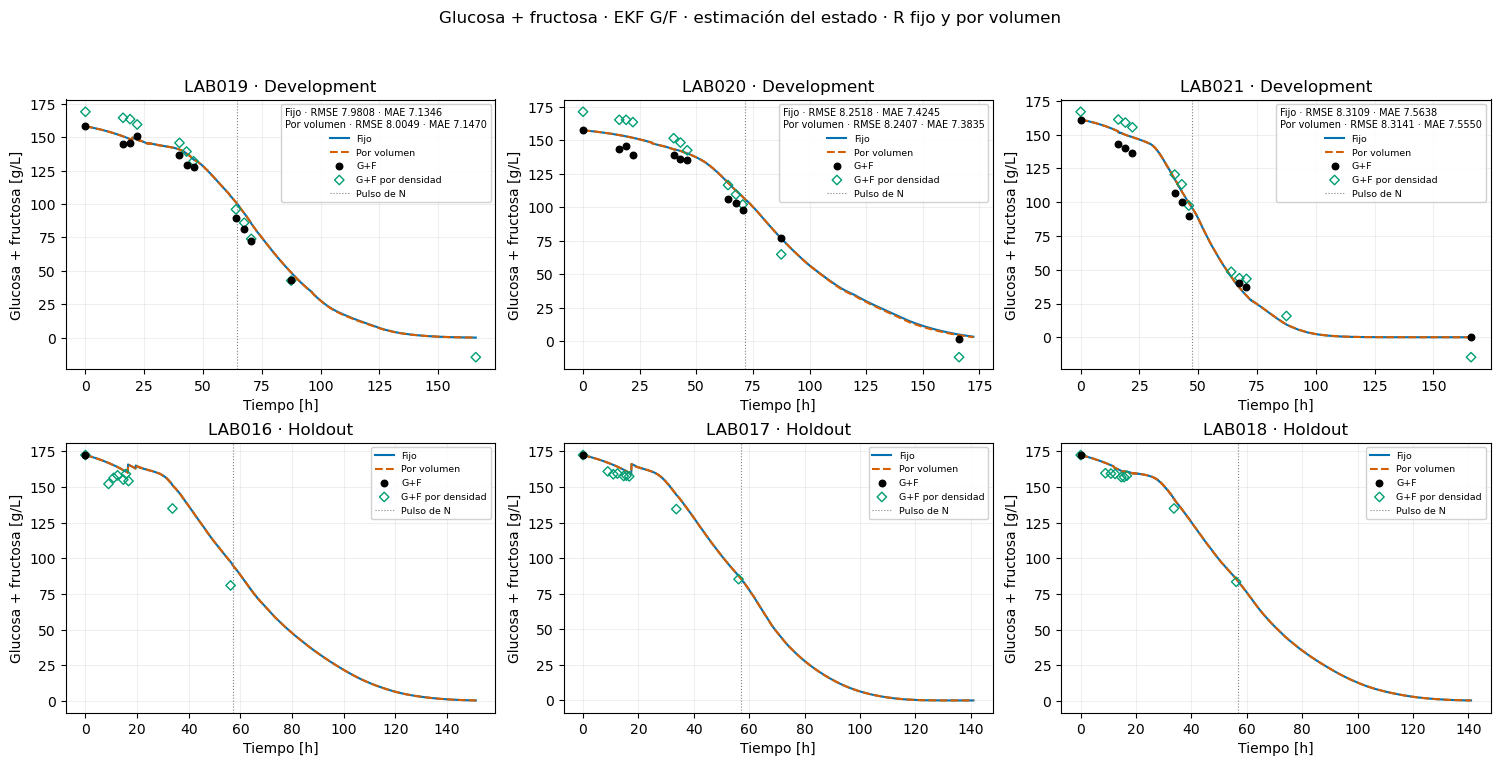

In [8]:
compare('GF', 'Glucosa + fructosa')

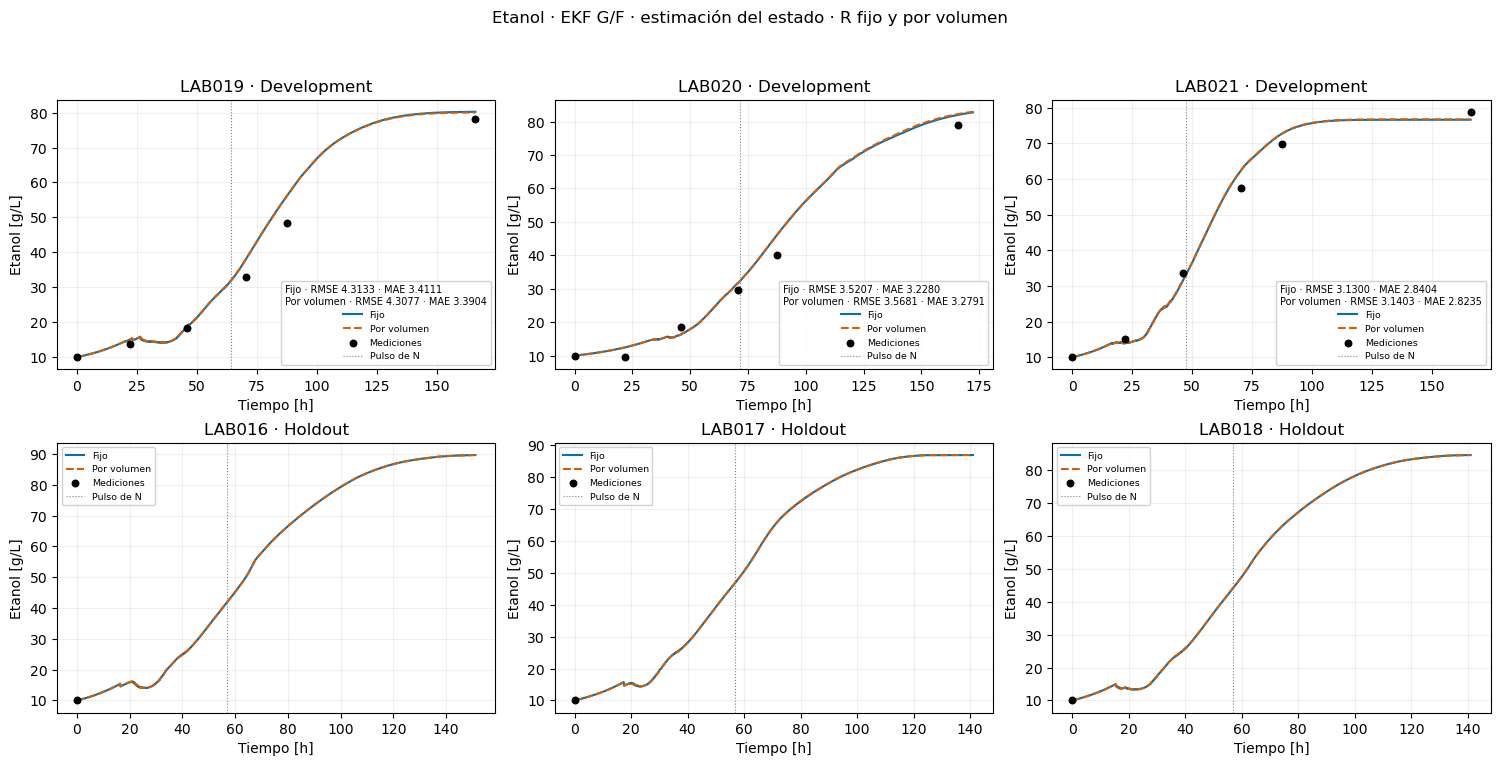

In [9]:
compare('E', 'Etanol')

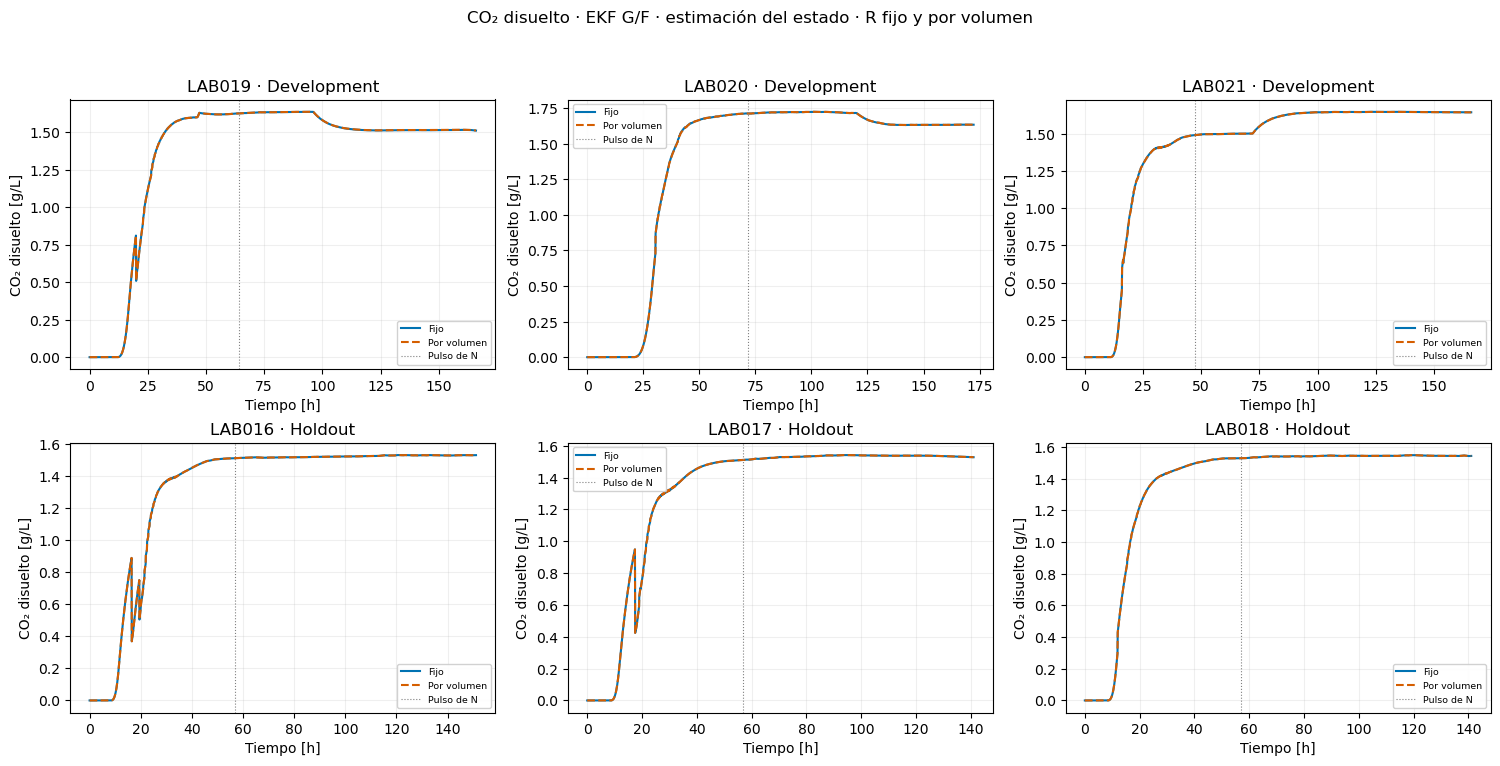

In [10]:
compare('Cd', 'CO₂ disuelto')

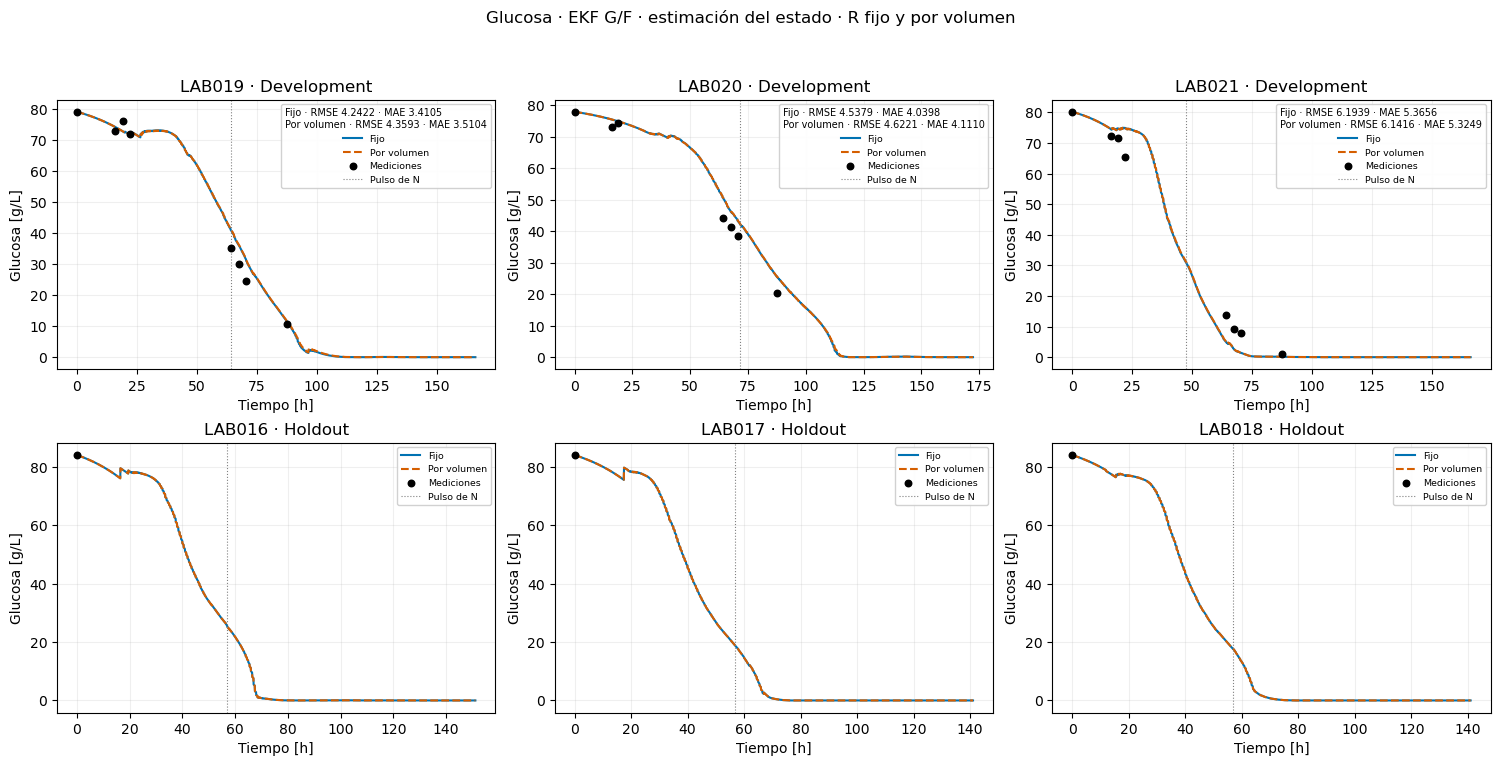

In [11]:
compare('G', 'Glucosa')

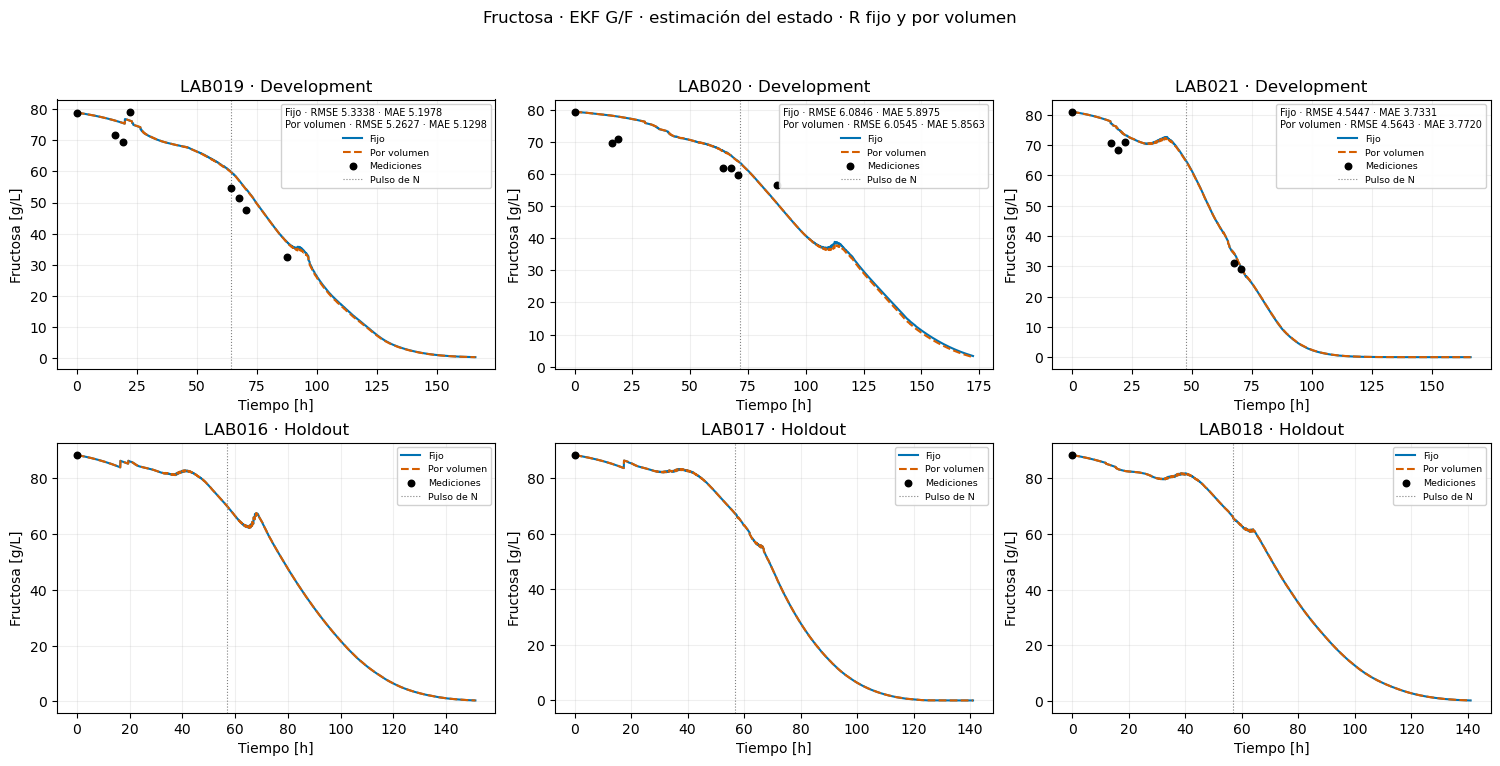

In [12]:
compare('F', 'Fructosa')

## Alcance para la memoria

El caso por volumen propaga la misma incertidumbre en SCCM² a las unidades de cada observación. El caso fijo conserva una aproximación a 2 L. Los errores de predicción y los diagnósticos de innovación permiten evaluar el efecto práctico de esa diferencia. El conjunto de validación tiene observaciones de CO₂ y biomasa. Los otros estados se evalúan en desarrollo.

La comparación mide sensibilidad bajo los supuestos del escenario de la ficha técnica. La varianza de los promedios de 30 minutos en condiciones de operación sigue por determinar experimentalmente.

**Resultado observado.** En LAB019–021, el volumen llegó a 1,75 L en ventanas asimiladas y \(R_k\) alcanzó 0,002848, un 30,6 % más que el valor fijo. El RMSE medio de CO₂ cambió de 0,07399 a 0,07354 g/(L·h) (−0,61 %) y el de biomasa de 0,71986 a 0,71770 g/L (−0,30 %). Las demás métricas medias de desarrollo variaron menos de 1 % en valor absoluto.

En LAB016–018, todas las lecturas de las ventanas asimiladas se convirtieron con 2 L. Por ello las dos configuraciones aplicaron la misma \(R\) y dieron las mismas métricas. La validación disponible carece de ventanas asimiladas con cambios de volumen para evaluar la diferencia.

Para la memoria, \(R_k\) por volumen tiene una justificación directa si se parte de una incertidumbre constante en SCCM². El \(R\) fijo a 2 L es una aproximación cuyo impacto observado en los RMSE medios fue pequeño en estos lotes de desarrollo.